In [1]:
import PyDSTool as dst
import numpy as np
import matplotlib.pyplot as plt
from PyDSTool.Toolbox import phaseplane as pp


In [2]:
DSargs = dst.args(name='Lorenz')
pars = {
    "C": 2.0,
    "g_K_bar": 20.0,
    "g_Na_bar" : 20.0,
    "g_NaP_bar" : 0.12,
    "g_shunt" : 2.0,
    "g_adapt_bar" : 1.0,
    "E_K" : -100,
    "E_Na" : 50,
    "E_shunt" : -70,
    "phi_w": 0.25,
    "tau_z": 200,
    "beta_w": -9.0,
    "beta_z": -30,
    "beta_m": -1.2,
    "beta_p": -52.0,
    "gamma_w": 10,
    "gamma_z": 5.0,
    "gamma_m": 18,
    "gamma_p": 12.0,
    "I_stim": 45.0
}

# Define aux functions
fnspecs = {
    "m_inf": (['V'], "0.5*(1+tanh((V-beta_m)/gamma_m))"),
    "w_inf": (['V'], "0.5*(1+tanh((V-beta_w)/gamma_w))"),
    "tau_w": (['V'], "1/(cosh((V-beta_w)/(2*gamma_w)))"),
    "p_inf": (['V'], "0.5*(1+tanh((V-beta_p)/gamma_p))"),
    "I_NaP": (['V'], "g_NaP_bar*p_inf(V)*(V-E_Na)"),
    
}


# Define the ODEs.
varspecs = {
    "V":  "(I_stim  - g_Na_bar*m_inf(V)*(V-E_Na) - I_NaP(V) -  g_K_bar*w*(V-E_K)- g_shunt*(V-E_shunt) - g_adapt_bar*z*(V-E_K))/C",
    "w": "phi_w*(w_inf(V)-w)/tau_w(V)",
    "z": "1/tau_z*(1/(1+exp((beta_z-V)/gamma_z))-z)",

}

# Define the initial conditions. These are the initial conditions for the ODE. In our case, we just have a single ODE such that x(t).
ics = {
    "V": -70,
    "w": 0,
    "z": 0
}   

# Define a domain for V. It is needed when finding steady states.
domain = {
    "V": [-100, 100],
    "w": [0, 1],
    "z": [0, 1]
}


DSargs.pars = pars
DSargs.fnspecs = fnspecs
DSargs.varspecs = varspecs
DSargs.ics = ics
DSargs.xdomain = domain

Computing trajectory...
Plotting trajectory part A...


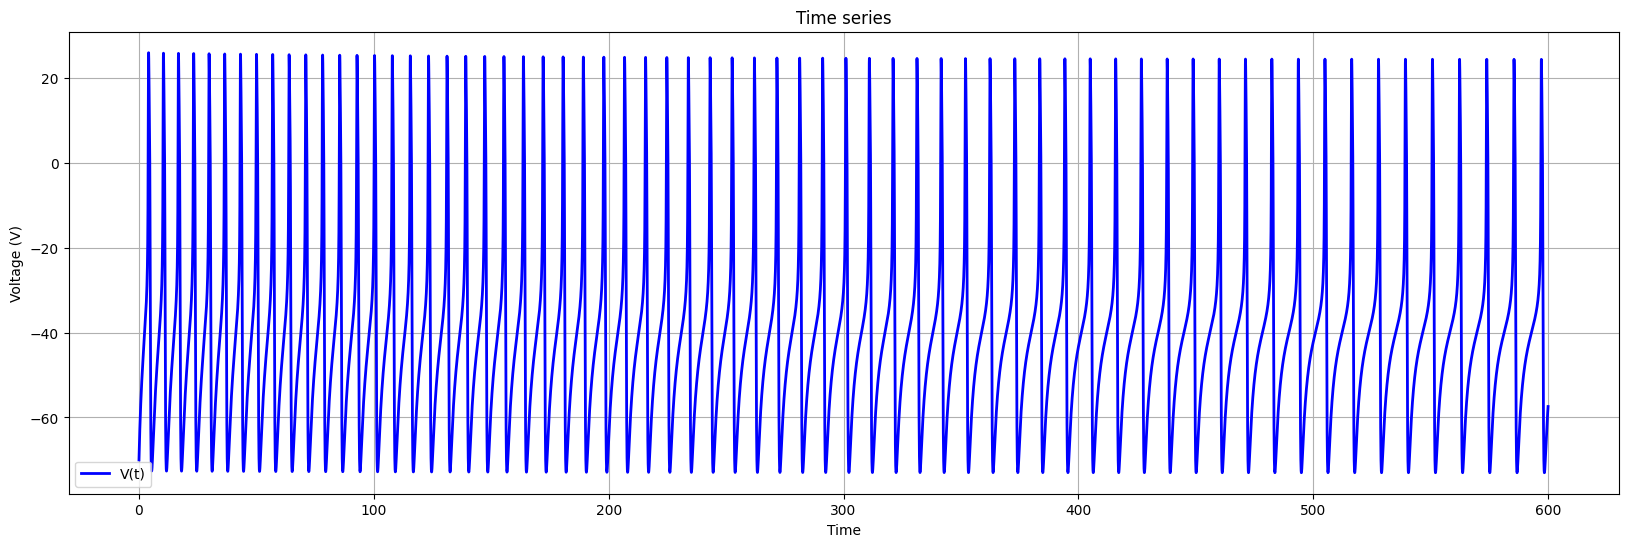

In [3]:

# 2. Compute the trajectory

# We choose which integrator to use, in this case it uses scipy' VODE
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

# Define the range of time.
ode_sys.set(tdata=[0, 600])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

# 3. Plotting Part A: Time Series and Basic Trajectory
print("Plotting trajectory part A...")
plt.figure(figsize=(20, 6))
plt.plot(points['t'], points['V'], 'b', lw =2, label = 'V(t)')
plt.xlabel('Time')
plt.ylabel("Voltage (V)")
plt.title('Time series')
plt.grid(True)
plt.legend()
plt.show()


Plotting trajectory part A...


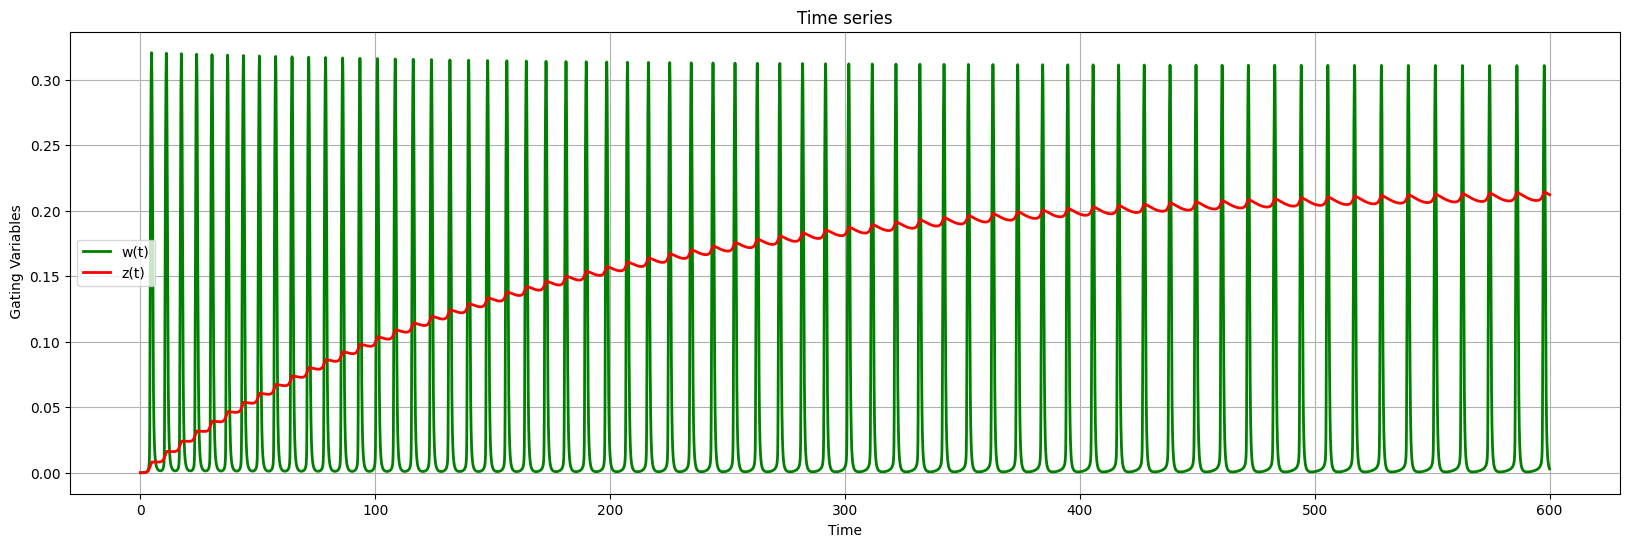

In [4]:


# 3. Plotting Part A: Time Series and Basic Trajectory
print("Plotting trajectory part A...")
plt.figure(figsize=(20, 6))
plt.plot(points['t'], points['w'], 'g', lw = 2, label = "w(t)")
plt.plot(points['t'], points['z'], 'r', lw = 2, label = "z(t)")
plt.xlabel('Time')
plt.ylabel(" Gating Variables")
plt.title('Time series')
plt.grid(True)
plt.legend()
plt.show()


In [5]:
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

# Define the range of time.
ode_sys.set(tdata=[0, 30])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

fp_coord = pp.find_fixedpoints(ode_sys, n = 4, eps = 1e-8)[0]
print(fp_coord)
pycont = dst.ContClass(ode_sys)
pcargs = dst.args(name='EQ1', type='EP-C')
pcargs.freepars = ['I_stim']
pcargs.MaxNumPoints = 200
pcargs.MaxStepSize = 1
pcargs.MinStepSize = 1e-3
pcargs.LocBifPoints = 'all'
pcargs.SaveEigen = True
pcargs.SaveJacobian = True

pcargs.initpoint = fp_coord
pcargs.verbosity = 2
pycont.newCurve(pcargs)
pycont["EQ1"].forward()
pycont["EQ1"].backward()

Computing trajectory...
{'V': -35.44319816464566, 'w': 0.005023263007554301, 'z': 0.25187453092820966}
Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 

Checking...
  |q| = 1.000000
  |<p,q> - 1| =  0.0
  |Aq - iwq| = 0.000000
  |A*p + iwp| = 0.000022

H Point found 
0 : 
V  =  -37.047419057670304
w  =  0.0036495913415240428
z  =  0.19631548560390827
I_stim  =  41.37259837233104

Eigenvalues = 

     (0.000000,0.152482)
     (0.000000,-0.152482)
     (-0.118905,0.000000)


w = 0.15248210284132444
l1 = -0.00547041655253145

B Point found 
0 : 
V  =  -99.99999999923693
w  =  1.2469252630431527e-08
z  =  8.315280277910348e-07
I_stim  =  -60.05726643884318

Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 



Plotting diagram.


Text(0.5, 1.0, 'Bifurcation in (I_stim, V) space')

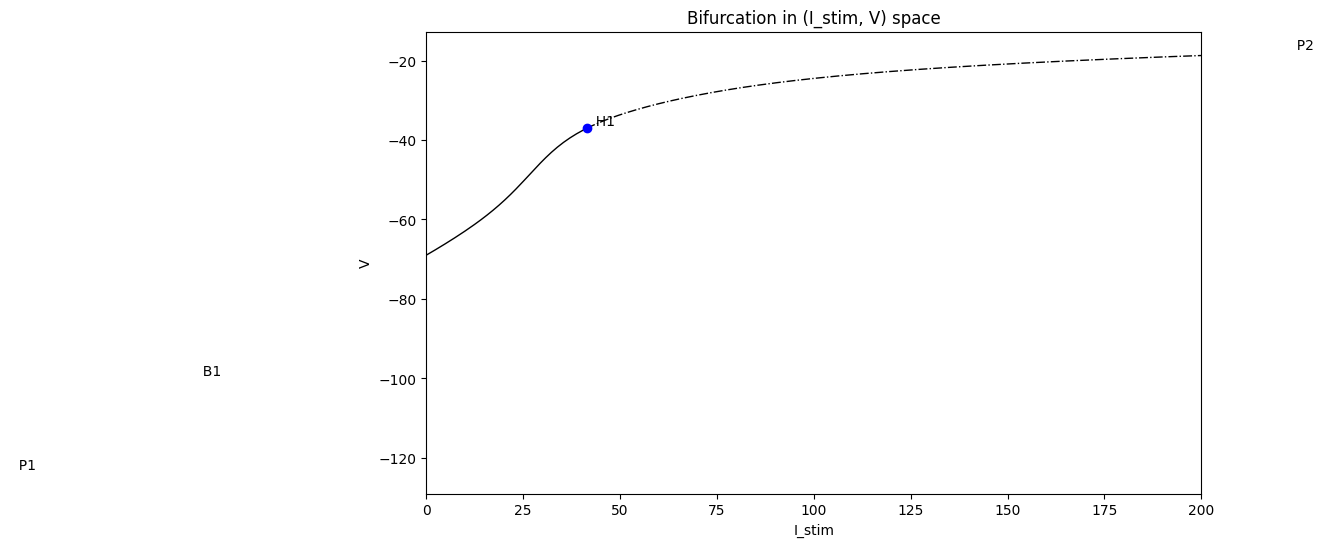

In [6]:
# 4. Plot the Results
print("Plotting diagram.")

plt.figure(figsize=(10, 6))
plt.xlim(0, 200)
pycont.display(('I_stim', 'V'), stability=True)
plt.title("Bifurcation in (I_stim, V) space")

In [7]:
DSargs1 = dst.args(name='Lorenz')
pars1 = {
    "C": 2.0,
    "g_K_bar": 20.0,
    "g_Na_bar" : 20.0,
    "g_NaP_bar" : 0.012,
    "g_shunt" : 2.0,
    "g_adapt_bar" : 1.0,
    "E_K" : -100,
    "E_Na" : 50,
    "E_shunt" : -70,
    "phi_w": 0.25,
    "tau_z": 200,
    "beta_w": -9.0,
    "beta_z": -30,
    "beta_m": -1.2,
    "beta_p": -52.0,
    "gamma_w": 10,
    "gamma_z": 5.0,
    "gamma_m": 18,
    "gamma_p": 12.0,
    "I_stim": 45.0
}

# Define aux functions
fnspecs1 = {
    "m_inf": (['V'], "0.5*(1+tanh((V-beta_m)/gamma_m))"),
    "w_inf": (['V'], "0.5*(1+tanh((V-beta_w)/gamma_w))"),
    "tau_w": (['V'], "1/(cosh((V-beta_w)/(2*gamma_w)))"),
    "p_inf": (['V'], "0.5*(1+tanh((V-beta_p)/gamma_p))"),
    "I_NaP": (['V'], "g_NaP_bar*p_inf(V)*(V-E_Na)"),
    
}


# Define the ODEs.
varspecs1 = {
    "V":  "(I_stim  - g_Na_bar*m_inf(V)*(V-E_Na) - I_NaP(V) -  g_K_bar*w*(V-E_K)- g_shunt*(V-E_shunt) - g_adapt_bar*z*(V-E_K))/C",
    "w": "phi_w*(w_inf(V)-w)/tau_w(V)",
    "z": "1/tau_z*(1/(1+exp((beta_z-V)/gamma_z))-z)",

}

# Define the initial conditions. These are the initial conditions for the ODE. In our case, we just have a single ODE such that x(t).
ics1 = {
    "V": -70,
    "w": 0,
    "z": 0
}   

# Define a domain for V. It is needed when finding steady states.
domain1 = {
    "V": [-100, 100],
    "w": [0, 1],
    "z": [0, 1]
}


DSargs1.pars = pars1
DSargs1.fnspecs = fnspecs1
DSargs1.varspecs = varspecs1
DSargs1.ics = ics1
DSargs1.xdomain = domain1

Computing trajectory...
Plotting trajectory part A...


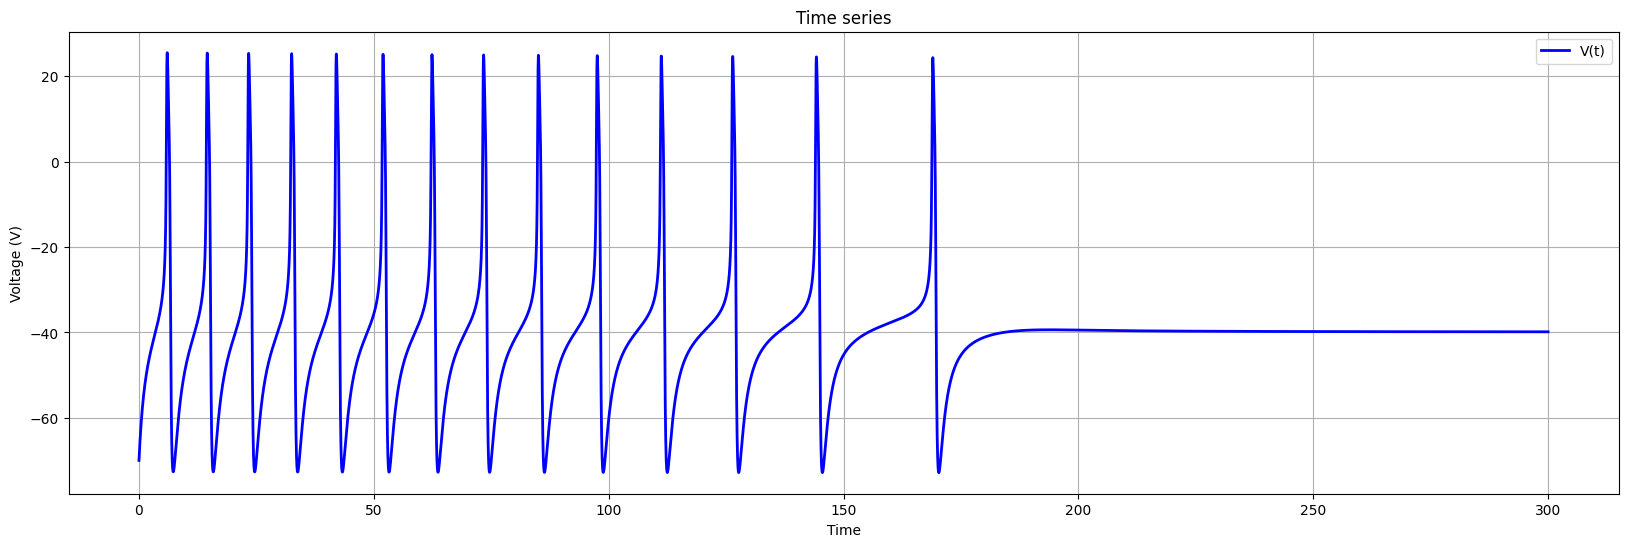

In [8]:

# 2. Compute the trajectory

# We choose which integrator to use, in this case it uses scipy' VODE
ode_sys1 = dst.Generator.Vode_ODEsystem(DSargs1)

# Define the range of time.
ode_sys1.set(tdata=[0, 300])

print("Computing trajectory...")
trajectory1 = ode_sys1.compute('dimensionless_run')
points1 = trajectory1.sample()

# 3. Plotting Part A: Time Series and Basic Trajectory
print("Plotting trajectory part A...")
plt.figure(figsize=(20, 6))
plt.plot(points1['t'], points1['V'], 'b', lw =2, label = 'V(t)')
plt.xlabel('Time')
plt.ylabel("Voltage (V)")
plt.title('Time series')
plt.grid(True)
plt.legend()
plt.show()


Plotting trajectory part A...


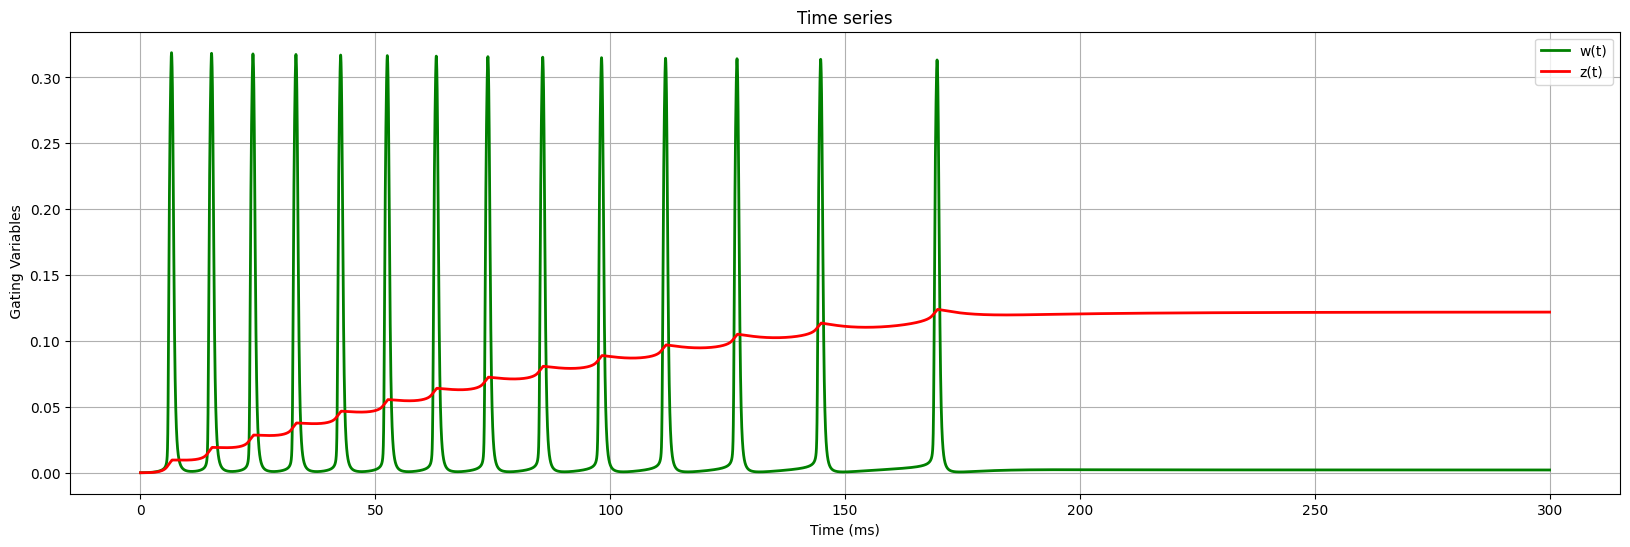

In [9]:


# 3. Plotting Part A: Time Series and Basic Trajectory
print("Plotting trajectory part A...")
plt.figure(figsize=(20, 6))
plt.plot(points1['t'], points1['w'], 'g', lw = 2, label = "w(t)")
plt.plot(points1['t'], points1['z'], 'r', lw = 2, label = "z(t)")
plt.xlabel('Time (ms)')
plt.ylabel(" Gating Variables")
plt.title('Time series')
plt.grid(True)
plt.legend()
plt.show()


In [10]:
ode_sys1 = dst.Generator.Vode_ODEsystem(DSargs1)

# Define the range of time.
ode_sys1.set(tdata=[0, 30])

print("Computing trajectory...")
trajectory1 = ode_sys1.compute('dimensionless_run')
points1 = trajectory1.sample()

fp_coord = pp.find_fixedpoints(ode_sys1, n = 4, eps = 1e-8)[0]
print(fp_coord)
pycont = dst.ContClass(ode_sys1)
pcargs = dst.args(name='EQ1', type='EP-C')
pcargs.freepars = ['I_stim']
pcargs.MaxNumPoints = 100
pcargs.MaxStepSize = 1
pcargs.MinStepSize = 1e-3
pcargs.LocBifPoints = 'all'
pcargs.SaveEigen = True
pcargs.SaveJacobian = True

pcargs.initpoint = fp_coord
pcargs.verbosity = 2
pycont.newCurve(pcargs)
pycont["EQ1"].forward()
pycont["EQ1"].backward()

Computing trajectory...
{'V': -39.86993386220073, 'w': 0.0020785857976230557, 'z': 0.12196131246230468}
Maximum test function iterations reached.

Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 



Plotting diagram.


Text(0.5, 1.0, 'Bifurcation in (I_stim, V) space')

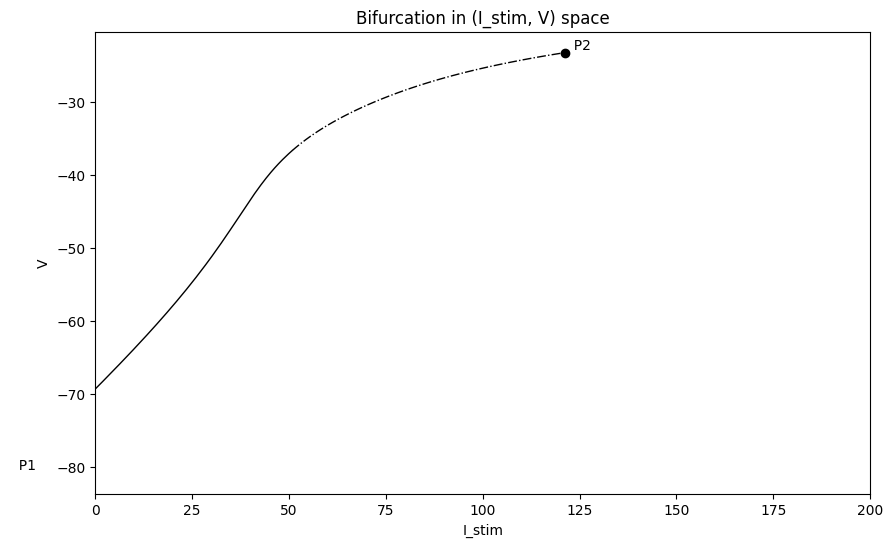

In [11]:
# 4. Plot the Results
print("Plotting diagram.")

plt.figure(figsize=(10, 6))
plt.xlim(0, 200)
pycont.display(('I_stim', 'V'), stability=True)
plt.title("Bifurcation in (I_stim, V) space")

In [ ]:
DSargs2 = dst.args(name='Lorenz')
pars2 = {
    "C": 2.0,
    "g_K_bar": 20.0,
    "g_Na_bar" : 20.0,
    "g_NaP_bar" : 0.012,
    "g_shunt" : 2.0,
    "g_adapt_bar" : 1.0,
    "E_K" : -100,
    "E_Na" : 50,
    "E_shunt" : -70,
    "phi_w": 0.25,
    "tau_z": 200,
    "beta_w": -9.0,
    "beta_z": -30,
    "beta_m": -1.2,
    "beta_p": -52.0,
    "gamma_w": 10,
    "gamma_z": 5.0,
    "gamma_m": 18,
    "gamma_p": 12.0,
    "I_stim": 45.0
}

# Define aux functions
fnspecs2 = {
    "m_inf": (['V'], "0.5*(1+tanh((V-beta_m)/gamma_m))"),
    "w_inf": (['V'], "0.5*(1+tanh((V-beta_w)/gamma_w))"),
    "tau_w": (['V'], "1/(cosh((V-beta_w)/(2*gamma_w)))"),
    "p_inf": (['V'], "0.5*(1+tanh((V-beta_p)/gamma_p))"),
    "I_NaP": (['V'], "g_NaP_bar*p_inf(V)*(V-E_Na)"),
    
}


# Define the ODEs.
varspecs2 = {
    "V":  "(I_stim  - g_Na_bar*m_inf(V)*(V-E_Na) - I_NaP(V) -  g_K_bar*w*(V-E_K) - g_shunt*(V-E_shunt) - g_adapt_bar*z*(V-E_K))/C",
    "w": "phi_w*(w_inf(V)-w)/tau_w(V)",
    "z": "1/tau_z*(1/(1+exp((beta_z-V)/gamma_z))-z)",

}

# Define the initial conditions. These are the initial conditions for the ODE. In our case, we just have a single ODE such that x(t).
ics2 = {
    "V": -70,
    "w": 0,
    "z": 0
}   

# Define a domain for V. It is needed when finding steady states.
domain2 = {
    "V": [-100, 100],
    "w": [0, 1],
    "z": [0, 1]
}


DSargs2.pars = pars2
DSargs2.fnspecs = fnspecs2
DSargs2.varspecs = varspecs2
DSargs2.ics = ics2
DSargs2.xdomain = domain2

In [ ]:
ode_sys2 = dst.Generator.Vode_ODEsystem(DSargs2)

# Define the range of time.
ode_sys2.set(tdata=[0, 30])

print("Computing trajectory...")
trajectory2 = ode_sys2.compute('dimensionless_run')
points2 = trajectory2.sample()

fp_coord = pp.find_fixedpoints(ode_sys2, n = 4, eps = 1e-8)[0]
print(fp_coord)
pycont = dst.ContClass(ode_sys2)
pcargs = dst.args(name='EQ1', type='EP-C')
pcargs.freepars = ['I_stim']
pcargs.MaxNumPoints = 200
pcargs.MaxStepSize = 1
pcargs.MinStepSize = 1e-3
pcargs.LocBifPoints = 'all'
pcargs.SaveEigen = True
pcargs.SaveJacobian = True

pcargs.initpoint = fp_coord
pcargs.verbosity = 2
pycont.newCurve(pcargs)
pycont["EQ1"].forward()
pycont["EQ1"].backward()

Computing trajectory...
{'V': -39.86993386220073, 'w': 0.0020785857976230557, 'z': 0.12196131246230468}
Checking...
  |q| = 1.000000
  |<p,q> - 1| =  1.6653345369377348e-16
  |Aq - iwq| = 0.000000
  |A*p + iwp| = 0.000028

H Point found 
0 : 
V  =  -36.96076968359157
w  =  0.0037131526207449064
z  =  0.19906411574737917
I_stim  =  50.234954285564065

Eigenvalues = 

     (0.000000,0.158213)
     (0.000000,-0.158213)
     (-0.111658,0.000000)


w = 0.15821347144312498
l1 = -0.012394589956224961

Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 

Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 

B Point found 
0 : 
V  =  -99.99999999907058
w  =  1.2469252630431533e-08
z  =  8.315280278186997e-07
I_stim  =  -60.05183376639721



Plotting diagram.


Text(0.5, 1.0, 'Bifurcation in (I_stim, V) space')

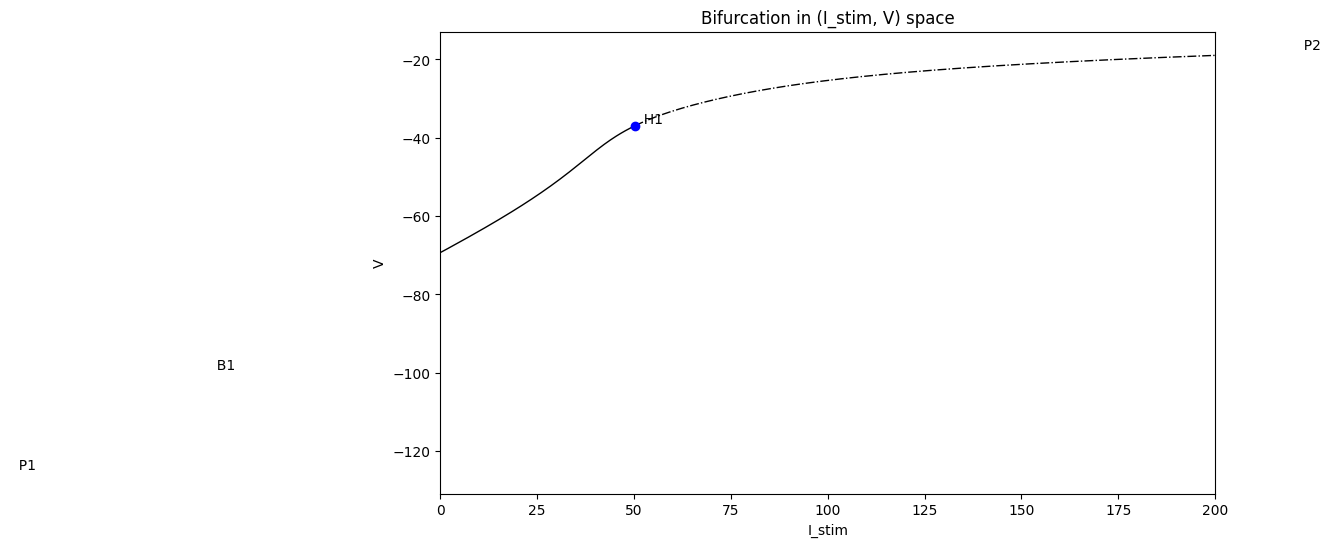

In [14]:
# 4. Plot the Results
print("Plotting diagram.")

plt.figure(figsize=(10, 6))
plt.xlim(0, 200)
pycont.display(('I_stim', 'V'), stability=True)
plt.title("Bifurcation in (I_stim, V) space")